# Deliverable 2 – Image processing: denoising photos with a convolutional auto-encoder

**Leyenda project – Data Science block**

The Leyenda pipeline has three steps: (1) classify images to keep only **photos**, (2) **clean** these photos, (3) generate a **caption** for them.
This notebook covers step 2: we remove the noise of RGB photographs so that they are easier to use for the Machine Learning algorithms that follow (captioning).

The method is a convolutional auto-encoder, adapted to real RGB photos.

**Contents**
1. File loading
2. Denoising with a convolutional auto-encoder (noise, model, training)
3. Case study: disappearance of the noise and loss of detail
4. Improving the model: more training examples from the same photos

## 0. Configuration

All the parameters are grouped here. **`DATA_DIR` must point to the folder of the dataset on your computer**: the loading code looks for the images in all its sub-folders.

In [17]:
import os, glob, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image, ImageOps
from scipy import ndimage
from sklearn.model_selection import train_test_split

# --- Parameters -------------------------------------------------------------
DATA_DIR    = r"C:\Projet data\Dataset Livrable 2 (1)\Dataset"   # the 148 noisy photos
IMG_SIZE    = 128            # images are resized to IMG_SIZE x IMG_SIZE (must be a multiple of 4)
MAX_IMAGES  = None           # e.g. 2000 to limit memory use, None = all images
BATCH_SIZE  = 16
EPOCHS      = 100            # maximum, EarlyStopping stops earlier if the model no longer improves
NOISE_MIN, NOISE_MAX = 0.05, 0.20   # range of noise std used for training (pixels in [0, 1])
NOISE_EVAL  = 0.10           # noise std used for the evaluation (= 25/255, the classic benchmark level)
MODEL_PATH  = "denoiser_rgb.keras"
SEED        = 42

keras.utils.set_random_seed(SEED)   # reproducible results (numpy, python and tensorflow seeds)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.22.0-rc0 | Keras 3.16.0.dev2026093004


## 1. File loading

The dataset contains RGB photos of **different sizes and formats**. A neural network needs inputs of a fixed size, so each image is:
1. opened with PIL and rotated according to its EXIF tag (photos taken in portrait mode),
2. converted to **RGB** (a grayscale, RGBA or CMYK file becomes a 3-channel image),
3. **cropped to a centred square** then resized to `IMG_SIZE × IMG_SIZE`: cropping before resizing keeps the proportions (no distortion of the objects),
4. normalised to **[0, 1]** (`/ 255`).

Unreadable files (corrupted, not an image) are skipped and listed instead of stopping the notebook.

In [18]:
EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp")

def list_image_files(folder):
    # All image files of the folder and its sub-folders, sorted for reproducibility
    files = [p for p in glob.glob(os.path.join(folder, "**", "*"), recursive=True)
             if p.lower().endswith(EXTENSIONS)]
    return sorted(files)

def load_image(path, size=IMG_SIZE):
    # Open -> EXIF orientation -> RGB -> centred square crop -> resize -> float32 in [0, 1]
    img = Image.open(path)
    img = ImageOps.exif_transpose(img).convert("RGB")
    img = ImageOps.fit(img, (size, size), method=Image.LANCZOS)
    return np.asarray(img, dtype=np.float32) / 255.

files = list_image_files(DATA_DIR)
if MAX_IMAGES:
    files = random.Random(SEED).sample(files, min(MAX_IMAGES, len(files)))
print(len(files), "image files found in", DATA_DIR)

images, kept, skipped = [], [], []
for f in files:
    try:
        images.append(load_image(f)); kept.append(f)
    except Exception as e:
        skipped.append((os.path.basename(f), type(e).__name__))

X = np.stack(images)
print("Loaded images:", X.shape, "| min", X.min(), "max", X.max())
print(len(skipped), "unreadable file(s) skipped", skipped[:5])

148 image files found in C:\Projet data\Dataset Livrable 2 (1)\Dataset
Loaded images: (148, 128, 128, 3) | min 0.0 max 1.0
0 unreadable file(s) skipped []


The data is split into **training** (70 %), **validation** (15 %, used during training to stop it at the right time) and **test** (15 %, never seen by the model, used for the case study).

train (103, 128, 128, 3) | validation (22, 128, 128, 3) | test (23, 128, 128, 3)


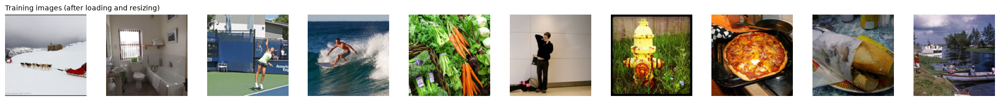

In [19]:
X_train, X_tmp = train_test_split(X, test_size=0.30, random_state=SEED)
X_val, X_test  = train_test_split(X_tmp, test_size=0.50, random_state=SEED)
print("train", X_train.shape, "| validation", X_val.shape, "| test", X_test.shape)

def show_rows(rows, titles, n=8, size=2.0):
    # Displays several series of images, one series per row
    n = min(n, len(rows[0]))
    fig, axes = plt.subplots(len(rows), n, figsize=(size * n, size * len(rows)), squeeze=False)
    for r, (imgs, title) in enumerate(zip(rows, titles)):
        for i in range(n):
            axes[r, i].imshow(np.clip(imgs[i], 0, 1))
            axes[r, i].axis("off")
        axes[r, 0].set_title(title, loc="left", fontsize=10)
    plt.tight_layout(); plt.show()

show_rows([X_train], ["Training images (after loading and resizing)"], n=10)

## 2. Denoising

### 2.1 Noise

The auto-encoder learns from pairs **(noisy image → clean image)**: the input is the noisy photo and the target is the original photo. Since we need the clean version of each image, the noise is added artificially.

We use **additive Gaussian noise** (`np.random.normal`), the classic model of the noise of a camera sensor:
`noisy = clip(image + N(0, σ²), 0, 1)`.

A strong noise such as σ = 0.5 destroys a photo, so we use σ = **0.10** (≈ 25/255, the reference level of denoising benchmarks) for the evaluation.

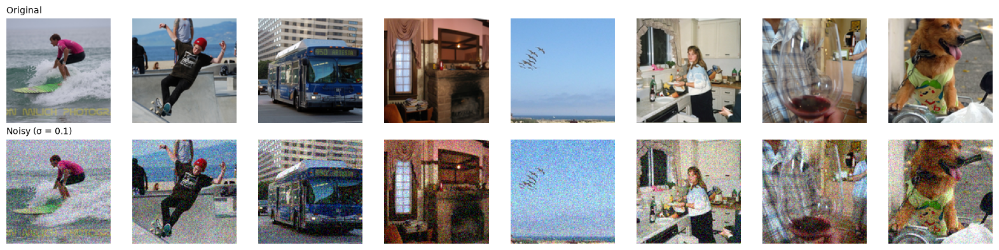

In [20]:
def add_gaussian_noise(x, std, seed=None):
    rng = np.random.default_rng(seed)
    return np.clip(x + rng.normal(0.0, std, size=x.shape), 0., 1.).astype(np.float32)

# Fixed noisy versions for validation and test: the evaluation is identical at each run
X_val_noisy  = add_gaussian_noise(X_val,  NOISE_EVAL, seed=1)
X_test_noisy = add_gaussian_noise(X_test, NOISE_EVAL, seed=2)

show_rows([X_test, X_test_noisy], ["Original", f"Noisy (σ = {NOISE_EVAL})"])

**Noise generated on the fly.**
If the noise were drawn only once, the model would see the same noisy images at each epoch and could memorise them. Instead, the training pipeline (`tf.data`):
* draws a **new noise at each epoch**, with a **random level σ between 0.05 and 0.20**: the model sees many more different examples and works even if the real noise level of a photo is unknown;
* applies a random **horizontal flip** (data augmentation), useful because the dataset is small.

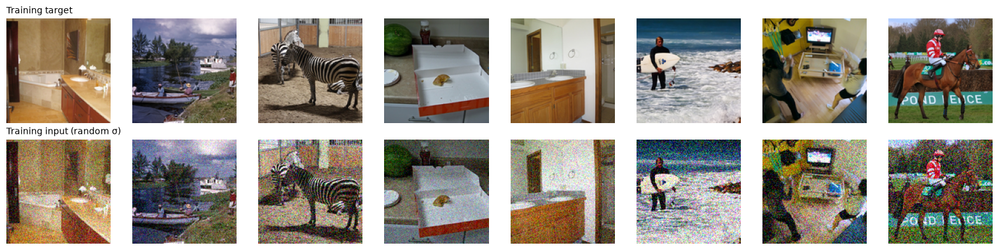

In [21]:
def make_noisy_pair(x):
    x = tf.image.random_flip_left_right(x)
    std = tf.random.uniform([], NOISE_MIN, NOISE_MAX)              # a different noise level per image
    noisy = tf.clip_by_value(x + tf.random.normal(tf.shape(x), stddev=std), 0., 1.)
    return noisy, x                                                 # (input, target)

train_ds = (tf.data.Dataset.from_tensor_slices(X_train)
            .shuffle(len(X_train), seed=SEED)
            .map(make_noisy_pair, num_parallel_calls=tf.data.AUTOTUNE)
            .batch(BATCH_SIZE)
            .prefetch(tf.data.AUTOTUNE))
val_ds = tf.data.Dataset.from_tensor_slices((X_val_noisy, X_val)).batch(BATCH_SIZE)

noisy_batch, clean_batch = next(iter(train_ds))
show_rows([clean_batch.numpy(), noisy_batch.numpy()], ["Training target", "Training input (random σ)"])

### 2.2 Convolutional auto-encoder

The structure, adapted to RGB images:
* **Encoder** – three convolutional layers (32, 64, 128 filters, 3×3, ReLU). The two `MaxPooling2D` divide the size by 4 (128×128 → 32×32): the network must keep only the useful information (shapes, colours), and the noise, which is random and cannot be compressed, is mostly eliminated.
* **Decoder** – the inverse: convolutions + `UpSampling2D` to go back to 128×128.
* **Output** – a convolution with **3 filters** (R, G, B) and a **sigmoid** activation, so that the pixels are between 0 and 1.

`padding='same'` keeps the spatial size inside each convolution. The model is fully convolutional, with 333,955 parameters.

**Loss**: `binary_crossentropy` suits images whose pixels are almost black or white. Photos have continuous colours, so we use the **mean squared error (MSE)**, which is directly linked to the PSNR.

**Metrics** (better = higher):
* **PSNR** (Peak Signal-to-Noise Ratio, in dB): measures the pixel-by-pixel error. +1 dB is a visible gain.
* **SSIM** (Structural Similarity, between 0 and 1): measures whether structures, contrasts and textures are preserved; closer to human perception.

In [22]:
def psnr(y_true, y_pred):
    return tf.image.psnr(y_true, y_pred, max_val=1.0)

def ssim(y_true, y_pred):
    return tf.image.ssim(y_true, y_pred, max_val=1.0)

def build_denoiser(img_size=IMG_SIZE):
    input_img = keras.Input(shape=(img_size, img_size, 3))

    # Encoder
    x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(input_img)
    x = layers.MaxPooling2D((2, 2), padding="same")(x)
    x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
    x = layers.MaxPooling2D((2, 2), padding="same")(x)
    encoded = layers.Conv2D(128, (3, 3), activation="relu", padding="same")(x)   # 32x32x128

    # Decoder
    x = layers.Conv2D(128, (3, 3), activation="relu", padding="same")(encoded)
    x = layers.UpSampling2D((2, 2))(x)
    x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
    x = layers.UpSampling2D((2, 2))(x)
    x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(x)
    decoded = layers.Conv2D(3, (3, 3), activation="sigmoid", padding="same")(x)  # RGB output in [0, 1]

    return keras.Model(input_img, decoded, name="denoiser")

autoencoder = build_denoiser()
autoencoder.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=[psnr, ssim])
autoencoder.summary()

Model: "denoiser"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 64, 64, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 128, 128, 32)   │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 128, 128, 3)    │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 333,955 (1.27 MB)

 Trainable params: 333,955 (1.27 MB)

 Non-trainable params: 0 (0.00 B)

### 2.3 Training

Three callbacks control the training (at most 100 epochs):
* **EarlyStopping**: stops the training when the validation loss no longer improves for 10 epochs and restores the best weights (avoids overfitting and saves time);
* **ReduceLROnPlateau**: divides the learning rate by 2 when the model stagnates, to refine the weights;
* **ModelCheckpoint**: saves the best model automatically (`.keras` format required by Keras 3).

In [23]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5),
    keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_loss", save_best_only=True),
]

history = autoencoder.fit(train_ds,
                          epochs=EPOCHS,
                          validation_data=val_ds,
                          callbacks=callbacks,
                          verbose=2)

Epoch 1/100


c:\Users\Ihssa\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


7/7 - 4s - 633ms/step - loss: 0.0673 - psnr: 12.1545 - ssim: 0.3179 - val_loss: 0.0453 - val_psnr: 13.6431 - val_ssim: 0.3678 - learning_rate: 0.0010
Epoch 2/100
7/7 - 2s - 223ms/step - loss: 0.0512 - psnr: 13.3960 - ssim: 0.3669 - val_loss: 0.0492 - val_psnr: 13.6619 - val_ssim: 0.3760 - learning_rate: 0.0010
Epoch 3/100
7/7 - 2s - 215ms/step - loss: 0.0439 - psnr: 13.9685 - ssim: 0.3759 - val_loss: 0.0482 - val_psnr: 13.4756 - val_ssim: 0.3564 - learning_rate: 0.0010
Epoch 4/100
7/7 - 2s - 218ms/step - loss: 0.0348 - psnr: 14.9766 - ssim: 0.3925 - val_loss: 0.0357 - val_psnr: 14.8068 - val_ssim: 0.3946 - learning_rate: 0.0010
Epoch 5/100
7/7 - 1s - 206ms/step - loss: 0.0320 - psnr: 15.2827 - ssim: 0.4031 - val_loss: 0.0407 - val_psnr: 14.3546 - val_ssim: 0.3772 - learning_rate: 0.0010
Epoch 6/100
7/7 - 1s - 205ms/step - loss: 0.0318 - psnr: 15.3495 - ssim: 0.4064 - val_loss: 0.0352 - val_psnr: 14.7927 - val_ssim: 0.4083 - learning_rate: 0.0010
Epoch 7/100
7/7 - 1s - 190ms/step - loss

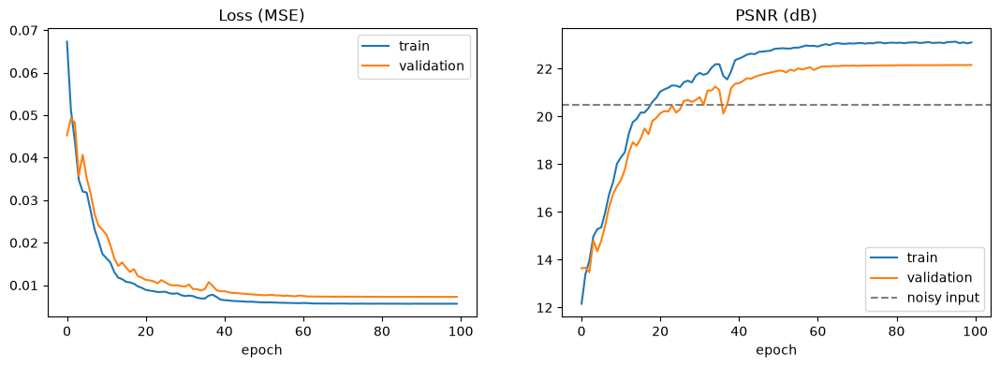

Best epoch: 100 / 100 | val PSNR 22.16 dB | val SSIM 0.656


In [24]:
# Learning curves
h = history.history
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="validation")
ax[0].set_title("Loss (MSE)"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h["psnr"], label="train"); ax[1].plot(h["val_psnr"], label="validation")
ax[1].axhline(float(tf.reduce_mean(psnr(X_val, X_val_noisy))), color="grey", ls="--", label="noisy input")
ax[1].set_title("PSNR (dB)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.show()
best = int(np.argmin(h["val_loss"]))
print(f"Best epoch: {best + 1} / {len(h['loss'])} | val PSNR {h['val_psnr'][best]:.2f} dB | val SSIM {h['val_ssim'][best]:.3f}")

**What we see on the curves.**

The two losses drop very fast during the first 15 epochs, then flatten out: on validation the MSE goes from 0.045 to 0.0072. The good news is that the validation curve stays right next to the training one and never goes back up, so the model is not overfitting.

On the PSNR graph, the validation curve only passes the grey line (the noisy images, about 20.5 dB) at epoch 27, and ends at **22.16 dB** (SSIM 0.656). So in the end the model gains less than 2 dB compared to doing nothing.

One thing surprised us at first: the output says "Best epoch: 100 / 100", as if the model still needed more epochs. Looking at the log, it is not really the case: from epoch 70 the validation loss stays stuck around 0.0073 and the PSNR only gains 0.03 dB. The learning rate was halved 7 times (between epochs 40 and 79) and reached its minimum, and EarlyStopping never kicked in because these tiny gains still count as improvements. In practice, the model had already learned everything it could around epoch 70. The whole training took about 3 minutes.

The best model is saved in `denoiser_rgb.keras`. It can be reloaded later (for instance in the captioning part of the pipeline) without training again:

In [25]:
denoiser = keras.models.load_model(MODEL_PATH, compile=False)   # compile=False: inference only
print("Model reloaded:", denoiser.name, "| input", denoiser.input_shape, "| output", denoiser.output_shape)

Model reloaded: denoiser | input (None, 128, 128, 3) | output (None, 128, 128, 3)


## 3. Case study

We now apply the denoiser to the **test images** (never used during training) and study what it removes (the noise) and what it also removes by mistake (the details).

### 3.1 Visual result

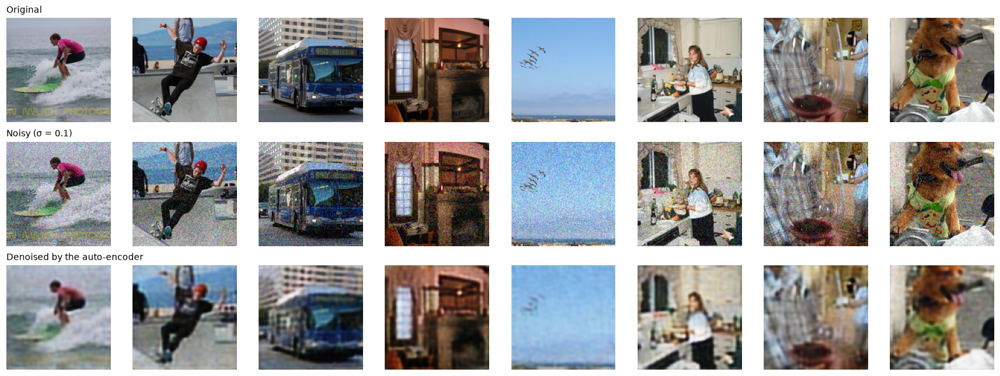

In [26]:
X_test_denoised = denoiser.predict(X_test_noisy, batch_size=BATCH_SIZE, verbose=0)

show_rows([X_test, X_test_noisy, X_test_denoised],
          ["Original", f"Noisy (σ = {NOISE_EVAL})", "Denoised by the auto-encoder"])

### 3.2 Quantitative evaluation and comparison with classical filters

To judge the auto-encoder, we compare it with the convolution filters seen last year, applied to the same noisy images:
* **Gaussian blur** (σ = 1): averages the neighbouring pixels;
* **median filter** (3×3): replaces each pixel with the median of its neighbourhood.

We also measure the **sharpness** of the images with the *variance of the Laplacian* (the Laplacian detects edges and fine textures): if the denoised image is less sharp than the original, details have been lost. Noise artificially increases this value, so the noisy image always looks "sharper" than the original.

In [27]:
def per_image_scores(clean, pred):
    return (psnr(clean, pred).numpy(), ssim(clean, pred).numpy())

def sharpness(imgs):
    # Variance of the Laplacian of the grayscale image: high = many edges / fine details
    gray = imgs.mean(axis=-1)
    return np.array([ndimage.laplace(g).var() for g in gray])

gauss  = np.stack([ndimage.gaussian_filter(im, sigma=(1, 1, 0)) for im in X_test_noisy])
median = np.stack([ndimage.median_filter(im, size=(3, 3, 1)) for im in X_test_noisy])

methods = {"Noisy (no processing)": X_test_noisy,
           "Gaussian blur (σ=1)": gauss,
           "Median filter 3x3": median,
           "Convolutional auto-encoder": X_test_denoised}

sharp_orig = sharpness(X_test).mean()
rows = []
for name, pred in methods.items():
    p, s = per_image_scores(X_test, pred)
    rows.append({"Method": name, "PSNR (dB)": p.mean(), "SSIM": s.mean(),
                 "Sharpness / original (%)": 100 * sharpness(pred).mean() / sharp_orig})
results = pd.DataFrame(rows).set_index("Method").round(3)
display(results)

p_noisy, s_noisy = per_image_scores(X_test, X_test_noisy)
p_ae, s_ae = per_image_scores(X_test, X_test_denoised)
print(f"Auto-encoder: PSNR {p_noisy.mean():.2f} -> {p_ae.mean():.2f} dB ({p_ae.mean() - p_noisy.mean():+.2f} dB), "
      f"SSIM {s_noisy.mean():.3f} -> {s_ae.mean():.3f}; "
      f"improved on {np.mean(p_ae > p_noisy) * 100:.0f} % of the test images.")
print(f"Details: the denoised images keep {results.loc['Convolutional auto-encoder', 'Sharpness / original (%)']:.0f} % "
      f"of the sharpness of the originals.")

,PSNR (dB),SSIM,Sharpness / original (%)
Method,,,
Noisy (no processing),20.378000,0.463,263.618988
Gaussian blur (σ=1),24.750999,0.713,5.826000
Median filter 3x3,24.091999,0.627,27.363001
Convolutional auto-encoder,23.052000,0.674,4.222000


Auto-encoder: PSNR 20.38 -> 23.05 dB (+2.67 dB), SSIM 0.463 -> 0.674; improved on 91 % of the test images.
Details: the denoised images keep 4 % of the sharpness of the originals.


**What we get.**

The auto-encoder does its job: at σ = 0.10 the PSNR goes from 20.38 to 23.05 dB (+2.67 dB) and the SSIM from 0.46 to 0.67, and it improves 21 of the 23 test images.

But honestly, we expected it to beat the classical filters, and it doesn't. A simple Gaussian blur gets **24.75 dB** and an SSIM of **0.713**, better on both metrics, without any training. The median filter is in between (24.09 dB, but a lower SSIM of 0.627).

The sharpness column explains a lot: our denoised images only keep 4.2 % of the sharpness of the originals, even less than the Gaussian blur (5.8 %). In other words, our model is basically a very strong smoothing. We think the main reason is the amount of data: 103 training images of 128×128 pixels is too little for the network to learn anything smarter than averaging the pixels. We try to fix this in Section 4.

### 3.3 Disappearance of the noise vs loss of detail

To see this trade-off, we zoom on the most detailed area of a few test images and display two difference maps:
* **|noisy − denoised|** = what the model **removed**. If the denoising is good, it looks like random grain (the noise) with no visible shape;
* **|original − denoised|** = what is **missing** compared to the original. The errors are concentrated on the **edges and textures**: this is the loss of detail.

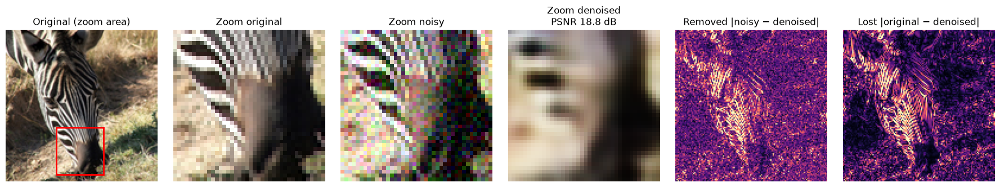

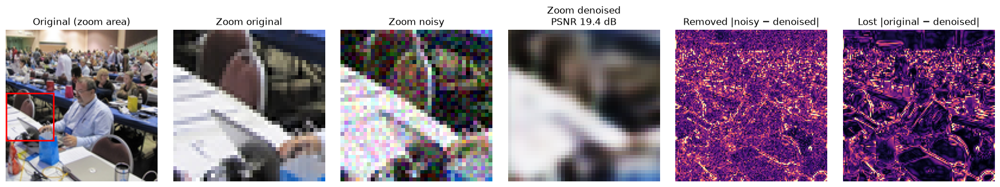

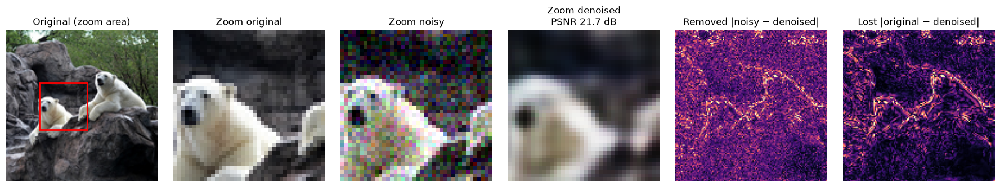

In [28]:
def most_detailed_crop(img, size=40):
    # Top-left corner of the size x size window with the highest local variance (most textured area)
    g = img.mean(axis=-1)
    var = ndimage.uniform_filter(g ** 2, size) - ndimage.uniform_filter(g, size) ** 2
    h = size // 2
    var = var[h:-h, h:-h]
    y, x = np.unravel_index(np.argmax(var), var.shape)
    return y, x

# Test images with the most details (highest sharpness), where the loss of detail is the most visible
idx = np.argsort(sharpness(X_test))[::-1][:3]
for i in idx:
    y, x = most_detailed_crop(X_test[i])
    crop = lambda im: im[y:y + 40, x:x + 40]
    removed = np.abs(X_test_noisy[i] - X_test_denoised[i]).mean(axis=-1)
    lost    = np.abs(X_test[i] - X_test_denoised[i]).mean(axis=-1)

    fig, ax = plt.subplots(1, 6, figsize=(18, 3.2))
    ax[0].imshow(X_test[i]); ax[0].add_patch(plt.Rectangle((x, y), 40, 40, fill=False, ec="red", lw=2))
    ax[0].set_title("Original (zoom area)")
    ax[1].imshow(crop(X_test[i]));          ax[1].set_title("Zoom original")
    ax[2].imshow(crop(X_test_noisy[i]));    ax[2].set_title("Zoom noisy")
    ax[3].imshow(crop(X_test_denoised[i])); ax[3].set_title(f"Zoom denoised\nPSNR {p_ae[i]:.1f} dB")
    ax[4].imshow(removed, cmap="magma", vmin=0, vmax=0.3); ax[4].set_title("Removed |noisy − denoised|")
    ax[5].imshow(lost,    cmap="magma", vmin=0, vmax=0.3); ax[5].set_title("Lost |original − denoised|")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

**What we notice.**

In the flat areas (sky, walls, skin) the grain is gone, which is what we wanted. But in the detailed areas, the result is much less convincing. The zebra is the clearest example: the stripes of the muzzle turn into a blur, and this image only gets 18.8 dB, well below the 23.05 dB average.

The two maps are interesting. We expected the *Removed* map to look like random grain, but the zebra stripes clearly show up in it: the model removed real details, not just noise. The *Lost* map confirms it, it lights up exactly on the edges and textures.

We think this comes from the architecture: the two `MaxPooling2D` shrink the image to 32×32, and anything finer than that cannot be rebuilt by the decoder.

### 3.4 Influence of the noise level

The model was trained with σ between 0.05 and 0.20. We now test it on noise levels from very low to higher than seen in training.

,PSNR noisy,PSNR denoised,SSIM noisy,SSIM denoised
σ,,,,
0.02,34.061001,22.926001,0.903,0.696
0.05,26.191999,23.136000,0.686,0.692
0.10,20.379000,23.048000,0.463,0.672
0.15,17.098000,22.681999,0.336,0.641
0.20,14.876000,22.107000,0.256,0.604
0.30,12.007000,20.525999,0.164,0.525


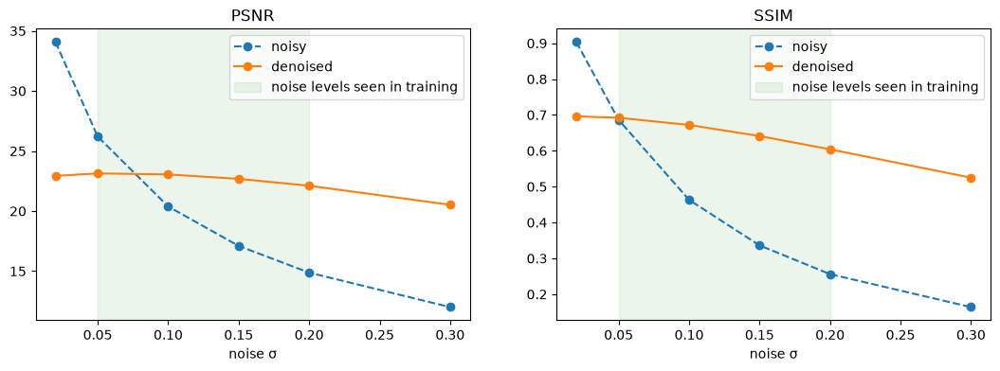

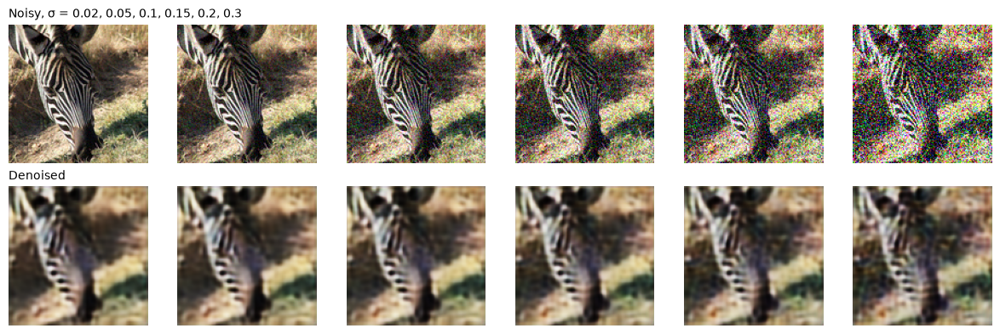

In [29]:
levels = [0.02, 0.05, 0.10, 0.15, 0.20, 0.30]
curve = []
for std in levels:
    noisy = add_gaussian_noise(X_test, std, seed=3)
    den = denoiser.predict(noisy, batch_size=BATCH_SIZE, verbose=0)
    curve.append({"σ": std,
                  "PSNR noisy": psnr(X_test, noisy).numpy().mean(), "PSNR denoised": psnr(X_test, den).numpy().mean(),
                  "SSIM noisy": ssim(X_test, noisy).numpy().mean(), "SSIM denoised": ssim(X_test, den).numpy().mean()})
curve = pd.DataFrame(curve).set_index("σ").round(3)
display(curve)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, metric in enumerate(["PSNR", "SSIM"]):
    ax[k].plot(levels, curve[f"{metric} noisy"], "o--", label="noisy")
    ax[k].plot(levels, curve[f"{metric} denoised"], "o-", label="denoised")
    ax[k].axvspan(NOISE_MIN, NOISE_MAX, color="green", alpha=0.08, label="noise levels seen in training")
    ax[k].set_xlabel("noise σ"); ax[k].set_title(metric); ax[k].legend()
plt.show()

# Same image at each noise level
i = idx[0]
noisy_row = [add_gaussian_noise(X_test[i:i + 1], s, seed=3)[0] for s in levels]
den_row = list(denoiser.predict(np.stack(noisy_row), verbose=0))
show_rows([noisy_row, den_row], ["Noisy, σ = " + ", ".join(map(str, levels)), "Denoised"], n=len(levels))

**What we notice.**

The most striking thing in this table is that the denoised image always ends up around **23 dB**, whatever the noise level (between 22.1 and 23.1 dB from σ = 0.02 to 0.20). It is as if the model had a ceiling it cannot go above.

This has two consequences:

- **when the noise is strong, the model is really useful**: +5.6 dB at σ = 0.15, +7.2 dB at σ = 0.20, and even +8.5 dB at σ = 0.30, a level it never saw during training;
- **when the noise is light, it makes things worse**: at σ = 0.02 the photo goes from 34.1 dB down to 22.9 dB, and at σ = 0.05 it still loses about 3 dB (only the SSIM stays about the same, 0.686 → 0.692). The model only starts to help from around σ = 0.07.

So for the pipeline, it would not make sense to denoise every photo with this model: we should first estimate the noise of each photo and only denoise the ones above about σ = 0.07.

### 3.5 Application to the photos of the dataset

Finally, we apply the denoiser directly to some **original photos** of the test set (without artificial noise), as it would be used in the Leyenda pipeline. If these photos contain real noise (grain, compression), it is attenuated; on clean photos, the result must stay faithful to the original.

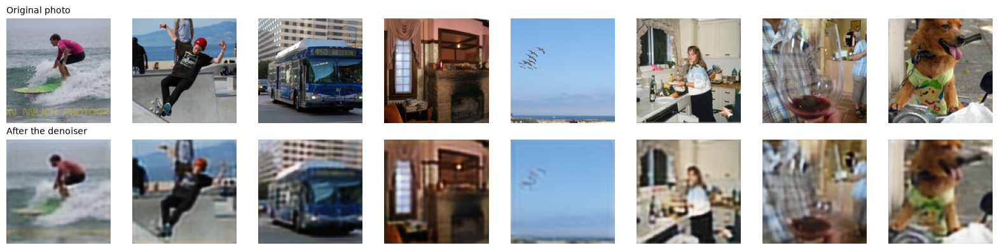

Fidelity to the original (PSNR between the photo and its denoised version): 22.74 dB


In [30]:
X_test_direct = denoiser.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
show_rows([X_test, X_test_direct], ["Original photo", "After the denoiser"])
p_direct = psnr(X_test, X_test_direct).numpy()
print(f"Fidelity to the original (PSNR between the photo and its denoised version): {p_direct.mean():.2f} dB")

**What we notice.** This is the test closest to real use, and it is a bit disappointing: the denoised photos are only 22.7 dB away from the originals, so the model changes them a lot. You can see it on the figure: everything is blurred, the text on the bus and the birds in the sky can no longer be read, and the faces lose their details. Since these photos have little noise, what the model removes here is mostly detail.

# 4. Improving the model: more training examples from the same photos

Our first model loses to a simple Gaussian blur. Looking at how a denoising auto-encoder is usually trained, the biggest difference is the amount of data: the classic example on handwritten digits trains on 60,000 images, we trained on 103.

We want to stay on the photos of this dataset, so instead of adding new images, we try to get much more out of the ones we have:

- **patches instead of whole images.** Instead of shrinking each photo to 128×128, we cut **64×64 patches at the original resolution**, 50 per training photo. That gives about 5,000 training examples instead of 103, and the patches keep all the details that the resizing was destroying;
- **more data augmentation.** On top of the horizontal flip, each patch is rotated by a random multiple of 90°, and it still gets a new random noise at every epoch;
- **a model that accepts any size.** Same layers as before, but with an input of shape `(None, None, 3)`, so that at the end it can denoise the photos at their real resolution.

Everything else stays the same (layers, loss, noise levels, callbacks), and we keep exactly the same split of the 148 photos as before, so any difference comes from the way we use the data. We also learned something from the first training: it ran all 100 epochs for gains of a few hundredths of a dB, so this time EarlyStopping gets a `min_delta`.

One limit we cannot remove without other data: the photos of the dataset are already slightly noisy, so our targets are still not perfectly clean.

Training patches: (5150, 64, 64, 3) | validation patches: (440, 64, 64, 3)


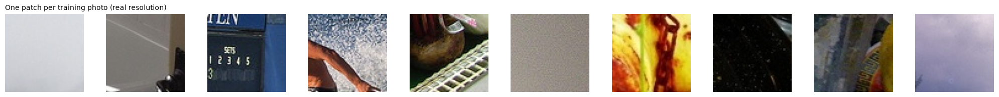

In [31]:
PATCH             = 64     # size of the training patches (multiple of 4)
PATCHES_PER_IMAGE = 50     # patches cut from each training photo
MODEL_PATH_V2     = "denoiser_rgb_v2.keras"

# Same split as in Section 1 (same function, same seed, same order), applied to the file names
files_train, files_tmp = train_test_split(kept, test_size=0.30, random_state=SEED)
files_val, files_test  = train_test_split(files_tmp, test_size=0.50, random_state=SEED)
assert np.allclose(load_image(files_test[0]), X_test[0])   # check: same test photos as the first model

def load_full(path):
    # Same as load_image, but without the crop and the resize: the photo keeps its real resolution
    img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    return np.asarray(img, dtype=np.float32) / 255.

def random_patches(img, n, size, rng):
    h, w = img.shape[:2]
    ys, xs = rng.integers(0, h - size + 1, n), rng.integers(0, w - size + 1, n)
    return np.stack([img[y:y + size, x:x + size] for y, x in zip(ys, xs)])

rng = np.random.default_rng(SEED)
P_train = np.concatenate([random_patches(load_full(f), PATCHES_PER_IMAGE, PATCH, rng) for f in files_train])
P_val   = np.concatenate([random_patches(load_full(f), 20, PATCH, rng) for f in files_val])
print(f"Training patches: {P_train.shape} | validation patches: {P_val.shape}")

show_rows([P_train[::PATCHES_PER_IMAGE]], ["One patch per training photo (real resolution)"], n=10)

The training is much longer than before (about 5,000 patches per epoch instead of 103 images): in our run it took between 17 and 33 seconds per epoch, about 24 minutes in total. The best model is saved in `denoiser_rgb_v2.keras`, next to the first one.

In [32]:
def make_noisy_pair_v2(x):
    x = tf.image.random_flip_left_right(x)
    x = tf.image.rot90(x, k=tf.random.uniform([], 0, 4, dtype=tf.int32))   # random rotation: 0, 90, 180 or 270°
    std = tf.random.uniform([], NOISE_MIN, NOISE_MAX)                       # same noise levels as before
    noisy = tf.clip_by_value(x + tf.random.normal(tf.shape(x), stddev=std), 0., 1.)
    return noisy, x

P_val_noisy = add_gaussian_noise(P_val, NOISE_EVAL, seed=1)

train_ds_v2 = (tf.data.Dataset.from_tensor_slices(P_train)
               .shuffle(len(P_train), seed=SEED)
               .map(make_noisy_pair_v2, num_parallel_calls=tf.data.AUTOTUNE)
               .batch(BATCH_SIZE)
               .prefetch(tf.data.AUTOTUNE))
val_ds_v2 = tf.data.Dataset.from_tensor_slices((P_val_noisy, P_val)).batch(BATCH_SIZE)

keras.utils.set_random_seed(SEED)
denoiser_v2 = build_denoiser(img_size=None)     # same layers as the first model, input of any size
denoiser_v2.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=[psnr, ssim])

callbacks_v2 = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, min_delta=1e-5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5),
    keras.callbacks.ModelCheckpoint(MODEL_PATH_V2, monitor="val_loss", save_best_only=True),
]

history_v2 = denoiser_v2.fit(train_ds_v2,
                             epochs=EPOCHS,
                             validation_data=val_ds_v2,
                             callbacks=callbacks_v2,
                             verbose=2)

Epoch 1/100


c:\Users\Ihssa\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


322/322 - 20s - 61ms/step - loss: 0.0136 - psnr: 21.2702 - ssim: 0.5713 - val_loss: 0.0076 - val_psnr: 23.3441 - val_ssim: 0.6097 - learning_rate: 0.0010
Epoch 2/100
322/322 - 17s - 54ms/step - loss: 0.0054 - psnr: 24.5709 - ssim: 0.6438 - val_loss: 0.0065 - val_psnr: 23.9492 - val_ssim: 0.6441 - learning_rate: 0.0010
Epoch 3/100
322/322 - 18s - 57ms/step - loss: 0.0045 - psnr: 25.4041 - ssim: 0.6724 - val_loss: 0.0055 - val_psnr: 25.0553 - val_ssim: 0.6682 - learning_rate: 0.0010
Epoch 4/100
322/322 - 19s - 60ms/step - loss: 0.0042 - psnr: 25.6439 - ssim: 0.6884 - val_loss: 0.0068 - val_psnr: 23.5368 - val_ssim: 0.6851 - learning_rate: 0.0010
Epoch 5/100
322/322 - 25s - 78ms/step - loss: 0.0038 - psnr: 26.1272 - ssim: 0.7027 - val_loss: 0.0049 - val_psnr: 25.6466 - val_ssim: 0.7023 - learning_rate: 0.0010
Epoch 6/100
322/322 - 25s - 79ms/step - loss: 0.0035 - psnr: 26.4825 - ssim: 0.7142 - val_loss: 0.0047 - val_psnr: 25.6714 - val_ssim: 0.7090 - learning_rate: 0.0010
Epoch 7/100
322/

### 4.1 Learning curves of the second model

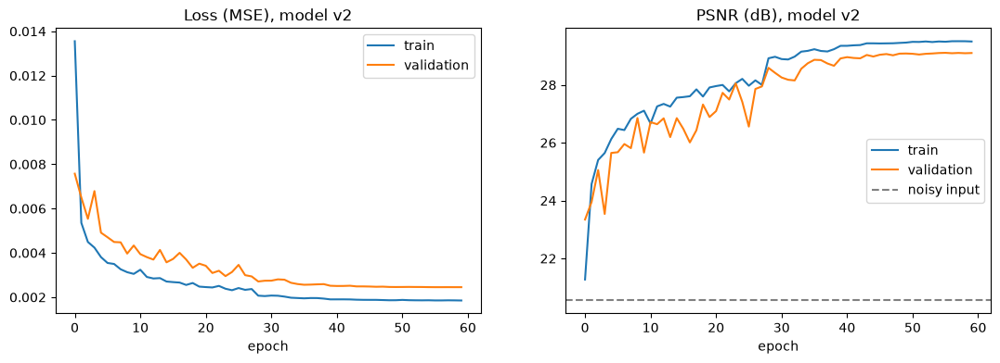

Best epoch: 59 / 60 | val PSNR 29.09 dB | val SSIM 0.805


In [33]:
h2 = history_v2.history
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(h2["loss"], label="train"); ax[0].plot(h2["val_loss"], label="validation")
ax[0].set_title("Loss (MSE), model v2"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h2["psnr"], label="train"); ax[1].plot(h2["val_psnr"], label="validation")
ax[1].axhline(float(tf.reduce_mean(psnr(P_val, P_val_noisy))), color="grey", ls="--", label="noisy input")
ax[1].set_title("PSNR (dB), model v2"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.show()

best2 = int(np.argmin(h2["val_loss"]))
print(f"Best epoch: {best2 + 1} / {len(h2['loss'])} | val PSNR {h2['val_psnr'][best2]:.2f} dB | val SSIM {h2['val_ssim'][best2]:.3f}")

**What we see.** The difference with the first model is obvious from the very first epoch: the validation PSNR is already at 23.3 dB after one epoch, which is more than the first model reached after 100 epochs.

The curves are a bit bumpy during the first 30 epochs (the validation PSNR goes up and down by 1 to 2 dB), then they become smooth once the learning rate is halved, from epoch 29. The training and validation curves stay close until the end (29.5 dB against 29.1 dB), so there is still no overfitting, even with a lot more training examples.

This time EarlyStopping did its job: thanks to `min_delta`, the training stopped by itself after 60 epochs, when the gains became negligible. The model ends at **29.09 dB** of validation PSNR and an SSIM of **0.805**, against 22.16 dB and 0.656 for the first model. Careful though, these two numbers are not measured on the same images (64×64 patches here, whole shrunk photos before), so the fair comparison is in the next part.

### 4.2 Comparison with the first model and the classical filters

We compare everything on the **same 23 test photos** as the first model, in two ways:

1. **exactly the setting of Section 3.2** (photos shrunk to 128×128, same noise σ = 0.10), to compare directly with the first table;
2. **at the real resolution**: a 128×128 square cut in the middle of each test photo, without resizing, which is closer to how the model will really be used.

In [34]:
def center_crop(img, size=IMG_SIZE):
    h, w = img.shape[:2]
    top, left = (h - size) // 2, (w - size) // 2
    return img[top:top + size, left:left + size]

def compare(clean, noisy, v1_pred, v2_pred):
    methods = {"Noisy (no processing)": noisy,
               "Gaussian blur (σ=1)": np.stack([ndimage.gaussian_filter(im, sigma=(1, 1, 0)) for im in noisy]),
               "Median filter 3x3": np.stack([ndimage.median_filter(im, size=(3, 3, 1)) for im in noisy]),
               "Auto-encoder v1": v1_pred,
               "Auto-encoder v2": v2_pred}
    sharp_clean = sharpness(clean).mean()
    rows = []
    for name, pred in methods.items():
        p, s = per_image_scores(clean, pred)
        rows.append({"Method": name, "PSNR (dB)": p.mean(), "SSIM": s.mean(),
                     "Sharpness / original (%)": 100 * sharpness(pred).mean() / sharp_clean})
    return pd.DataFrame(rows).set_index("Method").round(3)

# 1. Same setting as Section 3.2
X_test_v2 = denoiser_v2.predict(X_test_noisy, batch_size=BATCH_SIZE, verbose=0)
print("1. Photos shrunk to 128x128 (setting of Section 3.2)")
display(compare(X_test, X_test_noisy, X_test_denoised, X_test_v2))

# 2. Real resolution
T_test  = np.stack([center_crop(load_full(f)) for f in files_test])
T_noisy = add_gaussian_noise(T_test, NOISE_EVAL, seed=2)
T_v1 = denoiser.predict(T_noisy, batch_size=BATCH_SIZE, verbose=0)
T_v2 = denoiser_v2.predict(T_noisy, batch_size=BATCH_SIZE, verbose=0)
print("2. 128x128 squares at the real resolution")
display(compare(T_test, T_noisy, T_v1, T_v2))

1. Photos shrunk to 128x128 (setting of Section 3.2)


,PSNR (dB),SSIM,Sharpness / original (%)
Method,,,
Noisy (no processing),20.378000,0.463,263.618988
Gaussian blur (σ=1),24.750999,0.713,5.826000
Median filter 3x3,24.091999,0.627,27.363001
Auto-encoder v1,23.052000,0.674,4.222000
Auto-encoder v2,27.333000,0.843,50.817001


2. 128x128 squares at the real resolution


,PSNR (dB),SSIM,Sharpness / original (%)
Method,,,
Noisy (no processing),20.410000,0.409,236.897995
Gaussian blur (σ=1),25.327999,0.669,4.153000
Median filter 3x3,24.306000,0.565,22.111000
Auto-encoder v1,24.184999,0.662,3.195000
Auto-encoder v2,28.441999,0.814,43.141998


**What we get.** This is the result we were hoping for: **the second model beats the Gaussian blur, and by a lot.**

In the exact setting of Section 3.2 (same 23 photos, same noise):

| | PSNR | SSIM | Sharpness kept |
|---|---|---|---|
| Gaussian blur | 24.75 dB | 0.713 | 5.8 % |
| Auto-encoder v1 | 23.05 dB | 0.674 | 4.2 % |
| **Auto-encoder v2** | **27.33 dB** | **0.843** | **50.8 %** |

The second model gains **+6.95 dB** over the noisy images, +4.3 dB over the first model and +2.6 dB over the Gaussian blur. The jump in SSIM (0.84 against 0.67) shows that the structures of the images are much better preserved. And the sharpness column is maybe the most telling: the first model kept only 4 % of the sharpness of the originals, the second one keeps half of it. So it is not just a stronger blur anymore, it really removes the noise while keeping part of the details.

At the real resolution the conclusion is the same, and the gap is even a bit larger: 28.44 dB and SSIM 0.814 for the second model, against 25.33 dB for the Gaussian blur and 24.18 dB for the first model. This makes sense, since the second model was trained on patches at this resolution.

What made the difference? The architecture, the loss and the noise are exactly the same. The only change is how we used the 103 training photos: about 5,000 patches at their real resolution instead of 103 shrunk images.

### 4.3 Noise levels

Same test as Section 3.4 (same photos, same noise), for both models.

,PSNR noisy,PSNR v1,PSNR v2
σ,,,
0.02,34.060001,22.930000,28.530001
0.05,26.190001,23.139999,28.299999
0.10,20.379999,23.049999,27.330000
0.15,17.100000,22.680000,26.260000
0.20,14.880000,22.110001,25.250000
0.30,12.010000,20.530001,23.389999


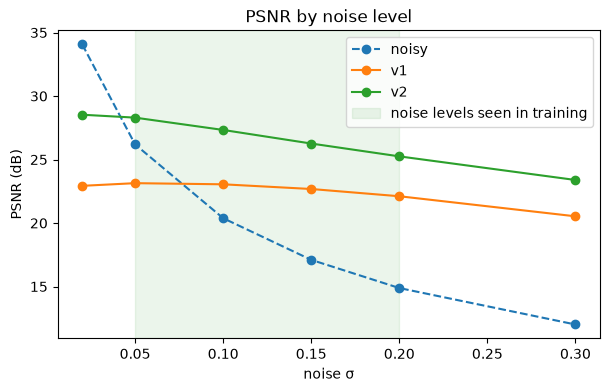

In [35]:
curve_v2 = []
for std in levels:
    noisy = add_gaussian_noise(X_test, std, seed=3)
    curve_v2.append({"σ": std,
                     "PSNR noisy": psnr(X_test, noisy).numpy().mean(),
                     "PSNR v1": psnr(X_test, denoiser.predict(noisy, batch_size=BATCH_SIZE, verbose=0)).numpy().mean(),
                     "PSNR v2": psnr(X_test, denoiser_v2.predict(noisy, batch_size=BATCH_SIZE, verbose=0)).numpy().mean()})
curve_v2 = pd.DataFrame(curve_v2).set_index("σ").round(2)
display(curve_v2)

plt.figure(figsize=(7, 4))
for col, style in [("PSNR noisy", "o--"), ("PSNR v1", "o-"), ("PSNR v2", "o-")]:
    plt.plot(levels, curve_v2[col], style, label=col.replace("PSNR ", ""))
plt.axvspan(NOISE_MIN, NOISE_MAX, color="green", alpha=0.08, label="noise levels seen in training")
plt.xlabel("noise σ"); plt.ylabel("PSNR (dB)"); plt.title("PSNR by noise level")
plt.legend(); plt.show()

**What we see.** The ceiling of the first model is gone, or at least much higher: the second model stays between 28.3 and 28.5 dB for light noise, instead of about 23 dB. It is better than the first model at every noise level, by 2.9 to 5.6 dB.

- **For strong noise** the gain becomes really big: +6.9 dB at σ = 0.10, +10.4 dB at σ = 0.20 and +11.4 dB at σ = 0.30, a level it never saw during training.
- **For light noise** it now helps much earlier: at σ = 0.05 it improves the image by 2.1 dB, where the first model lost 3 dB. The point where denoising becomes useful moves from about σ = 0.07 down to about σ = 0.04.
- **At σ = 0.02 it still makes the image worse** (34.1 → 28.5 dB), but much less than the first model (34.1 → 22.9 dB). Our model was trained with noise between 0.05 and 0.20, so it always expects a fair amount of noise to remove. For photos that are almost clean, it is still better not to denoise.

### 4.4 Visual comparison

The same test photos as in Section 3.1, then a zoom on the zebra of Section 3.3, for both models.

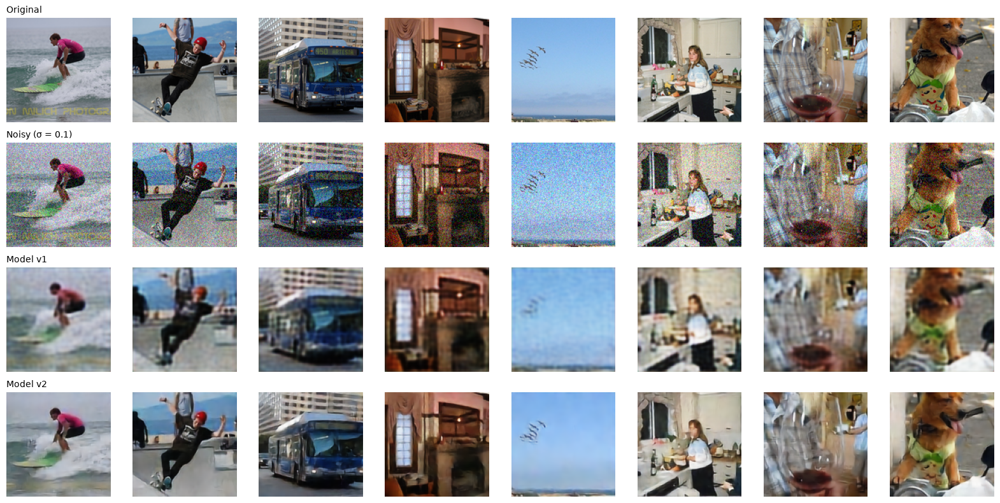

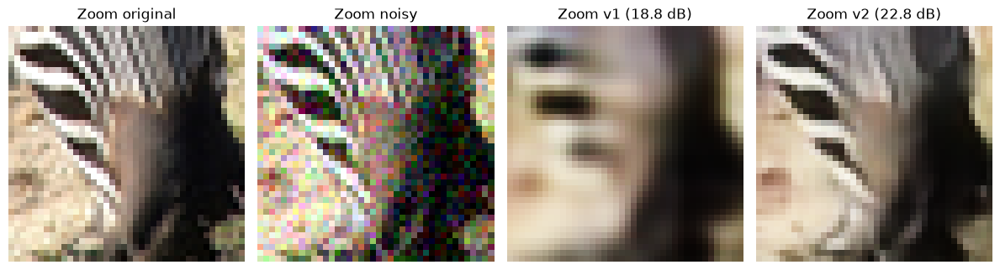

In [36]:
show_rows([X_test, X_test_noisy, X_test_denoised, X_test_v2],
          ["Original", f"Noisy (σ = {NOISE_EVAL})", "Model v1", "Model v2"])

i = idx[0]                                      # most detailed test photo (the zebra of Section 3.3)
y, x = most_detailed_crop(X_test[i])
zooms = [(X_test[i], "Zoom original"), (X_test_noisy[i], "Zoom noisy"),
         (X_test_denoised[i], f"Zoom v1 ({p_ae[i]:.1f} dB)"),
         (X_test_v2[i], f"Zoom v2 ({psnr(X_test[i], X_test_v2[i]).numpy():.1f} dB)")]
fig, ax = plt.subplots(1, 4, figsize=(12, 3.2))
for a, (im, title) in zip(ax, zooms):
    a.imshow(im[y:y + 40, x:x + 40]); a.set_title(title); a.axis("off")
plt.tight_layout(); plt.show()

**What we see.** The difference is visible at first sight. In the row of the first model, everything is blurred: the face of the surfer, the windows of the bus and the birds have almost disappeared. In the row of the second model, the images look very close to the originals: the red cap of the skater, the windows and the front of the bus, the birds in the sky are all still there, and the grain of the noise is gone.

The zoom on the zebra sums it up: with the first model the stripes of the muzzle merge into a blur (18.8 dB), with the second one they are clearly visible again (22.8 dB). The result is not perfect, the image is still a bit smoother than the original and the finest textures of the grass are softened, but the main details survive the denoising.

### 4.5 Back to the real photos

Finally, the real use: the test photos of the dataset, with their real noise and at their **real resolution**, through the second model (the first one only accepts 128×128 images). As in Section 3.5, these photos have little noise, so a good denoiser should change them as little as possible.

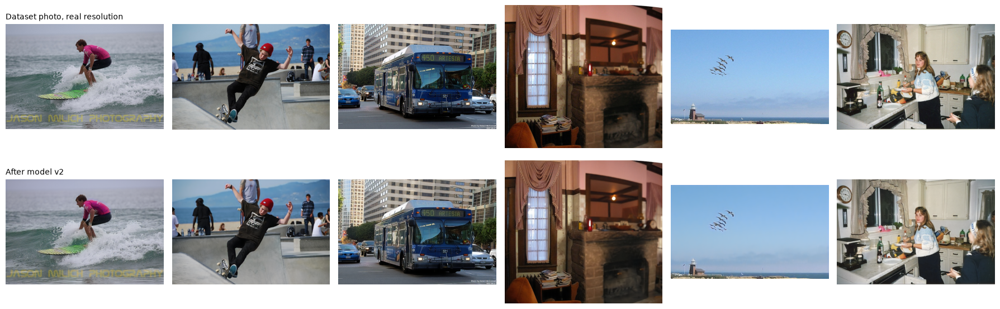

Fidelity to the original photos: v1 22.74 dB (photos shrunk to 128x128) | v2 30.00 dB (real resolution)


In [37]:
def denoise_full(model, img):
    # Pads the photo to a multiple of 4 (two poolings), denoises it and removes the padding
    h, w = img.shape[:2]
    padded = np.pad(img, ((0, (-h) % 4), (0, (-w) % 4), (0, 0)), mode="reflect")
    return model.predict(padded[None], verbose=0)[0, :h, :w]

full_test = [load_full(f) for f in files_test]
full_v2 = [denoise_full(denoiser_v2, im) for im in full_test]
show_rows([full_test, full_v2], ["Dataset photo, real resolution", "After model v2"], n=6, size=3.0)

fidelity_v2 = np.mean([psnr(a, b).numpy() for a, b in zip(full_test, full_v2)])
print(f"Fidelity to the original photos: v1 {p_direct.mean():.2f} dB (photos shrunk to 128x128) | "
      f"v2 {fidelity_v2:.2f} dB (real resolution)")

**What we see.** On the real photos, the second model behaves the way we want: the photos come out almost unchanged, at **30.0 dB** from the originals against 22.7 dB for the first model. On the figure it is hard to tell the two rows apart: the "450 ARTESIA" sign on the bus, the photographer's signature on the surf photo, the birds and the lighthouse are all still readable.

We have to be careful with this number, though. The first model was measured on photos shrunk to 128×128 and the second one at the real resolution, so the comparison is not perfectly fair. And since we do not have the clean version of these photos, we cannot say exactly how much of the difference is real noise removed and how much is detail lost. But visually, the model is now usable on the photos of the dataset, which was not the case before.

## Conclusion

**What we did.** We loaded the 148 photos of the dataset (any size and format, converted to RGB) and split them into 103 training, 22 validation and 23 test photos. We built a convolutional auto-encoder (333,955 parameters) that learns to rebuild a photo from a noisy version, with a new random noise at every epoch, and we trained it in two ways:

- **version 1**: on the 103 training photos shrunk to 128×128;
- **version 2**: same model, same loss, same noise, but on about 5,000 patches of 64×64 cut at the real resolution of the same 103 photos, with more data augmentation.

**What we found.**

- The first model removes the noise (+2.67 dB at σ = 0.10), but it is basically a strong blur: a simple Gaussian blur does better (24.75 dB against 23.05 dB), the images keep only 4 % of their sharpness, and the output never goes above about 23 dB.
- The second model fixes most of this. On the same test photos it reaches **27.33 dB and an SSIM of 0.843**, so it beats the Gaussian blur by 2.6 dB and the first model by 4.3 dB, and it keeps half of the sharpness. On the real photos of the dataset it changes them very little (30.0 dB) and the details stay readable.
- The case study shows the two sides of denoising: the noise disappears very well in flat areas, but the finest details are always a bit softened, and on almost clean photos (σ = 0.02) denoising still does more harm than good.

**What we learned.** The biggest improvement did not come from a bigger network but from the data: with the same 103 photos, cutting many patches at the real resolution instead of shrinking the whole photos gave +4.3 dB. A denoising auto-encoder needs many examples, and shrinking the images throws away the details we want to keep.

**Limits.** Our targets are still the photos of the dataset, which are slightly noisy themselves, so the model can never learn a perfectly clean result. And we only trained on Gaussian noise, which is not exactly the noise of old scanned photos.
